# Project 02: Data Visualization with Matplotlib & Seaborn


**Objective:** I use the restaurant *tips* dataset to make clear, honest charts (histogram, box plot, scatter plot, bar chart and a correlation heatmap), with a one-line takeaway under each.

## 1. Questions I want to answer
1. How are bill amounts distributed?
2. Do tips differ by day of the week?
3. Does a bigger bill mean a bigger tip?
4. Which numeric columns move together?



In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# One colour-blind friendly palette for the whole project (no red/green pairing)
sns.set_theme(style="whitegrid", palette="colorblind")
tips = sns.load_dataset("tips")

## 3. Quick look at the data

In [2]:
print("Rows, columns:", tips.shape)
tips.head()

Rows, columns: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
tips.info()
tips.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


**Columns:** `total_bill` (USD), `tip` (USD), `sex`, `smoker`, `day`, `time` (Lunch/Dinner), `size` (party size).
I also create `tip_pct` = tip as a percentage of the bill, because a fair comparison between days should not depend only on bill size.

In [4]:
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100
print("Missing values:", tips.isna().sum().sum())

Missing values: 0


## 4. Chart 1: How are bills distributed? (histogram)

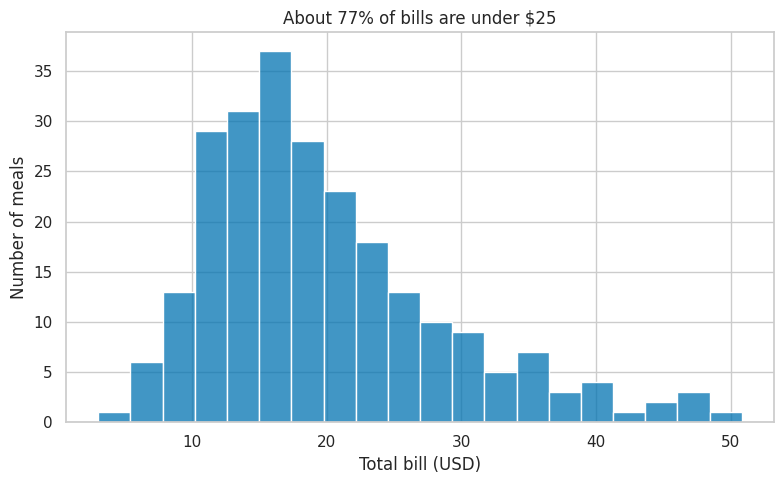

Takeaway: Most bills are between $13 and $24 (the middle half); the median bill is $17.80, with a long tail of a few large bills.


In [5]:
pct_under_25 = (tips["total_bill"] < 25).mean()

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(tips["total_bill"], bins=20, ax=ax)
ax.set(title=f"About {pct_under_25:.0%} of bills are under $25",
       xlabel="Total bill (USD)", ylabel="Number of meals")
plt.tight_layout()
plt.show()

print(f"Takeaway: Most bills are between ${tips['total_bill'].quantile(0.25):.0f} and "
      f"${tips['total_bill'].quantile(0.75):.0f} (the middle half); the median bill is "
      f"${tips['total_bill'].median():.2f}, with a long tail of a few large bills.")

## 5. Chart 2: Do tips differ by day? (box plot)

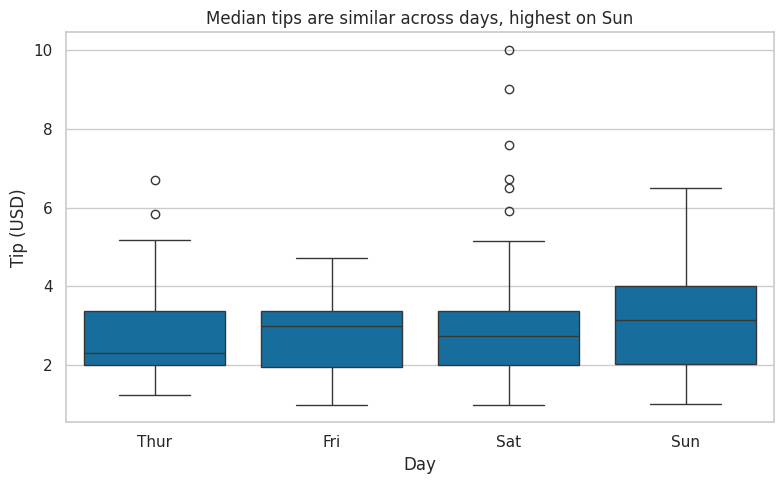

Takeaway: median tip by day -> Thur: $2.30, Fri: $3.00, Sat: $2.75, Sun: $3.15. The differences are small compared with the spread within each day.


In [6]:
med = tips.groupby("day", observed=True)["tip"].median()
top_day = med.idxmax()

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="tip", ax=ax)
ax.set(title=f"Median tips are similar across days, highest on {top_day}",
       xlabel="Day", ylabel="Tip (USD)")
plt.tight_layout()
plt.show()

print("Takeaway: median tip by day -> " + ", ".join(f"{d}: ${v:.2f}" for d, v in med.items())
      + ". The differences are small compared with the spread within each day.")

## 6. Chart 3: Does a bigger bill mean a bigger tip? (scatter plot)
Colour shows time of day (Lunch / Dinner). Both axes start at zero so the relationship is not exaggerated.

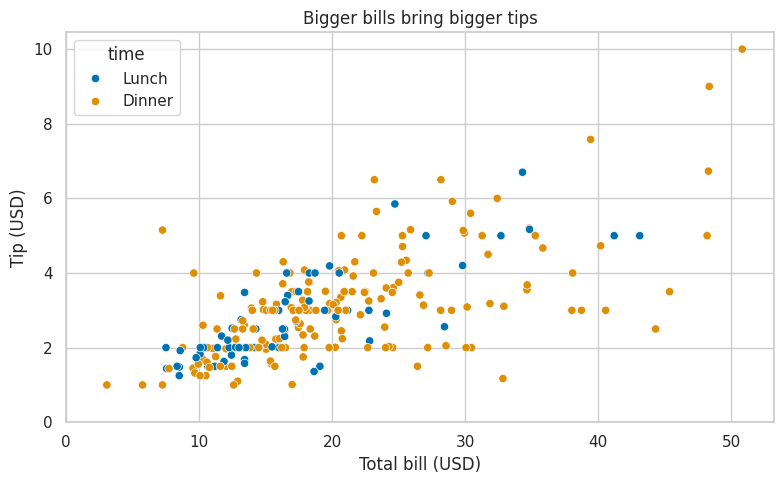

Takeaway: Tip rises with the bill (correlation r = 0.68), but the points are spread out, so the bill explains only part of the tip.


In [7]:
r = tips["total_bill"].corr(tips["tip"])

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", ax=ax)
ax.set(title="Bigger bills bring bigger tips",
       xlabel="Total bill (USD)", ylabel="Tip (USD)", xlim=(0, None), ylim=(0, None))
plt.tight_layout()
plt.show()

print(f"Takeaway: Tip rises with the bill (correlation r = {r:.2f}), but the points are spread out, "
      f"so the bill explains only part of the tip.")

## 7. Chart 4: Which numbers move together? (correlation heatmap)

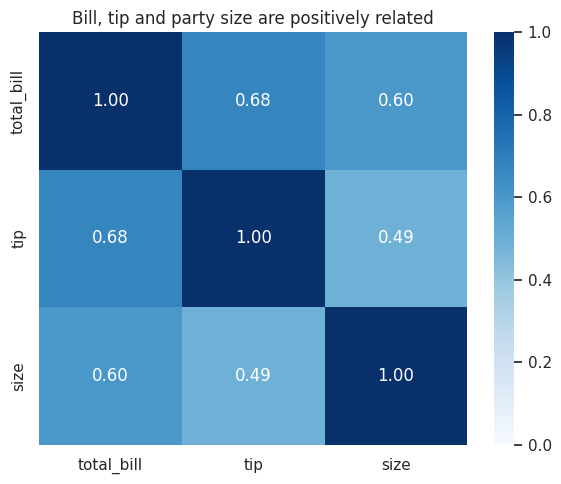

Takeaway: The strongest relationship is between total_bill and tip (r = 0.68). All three numbers are positively correlated, which is expected because bigger parties order more.


In [8]:
corr = tips.select_dtypes("number").drop(columns="tip_pct").corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Bill, tip and party size are positively related")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pair, val = upper.idxmax(), upper.max()
print(f"Takeaway: The strongest relationship is between {pair[0]} and {pair[1]} (r = {val:.2f}). "
      f"All three numbers are positively correlated, which is expected because bigger parties order more.")

## 8. Extra chart: Tip as a percentage of the bill (bar chart)
The axis starts at zero, as bar charts should.

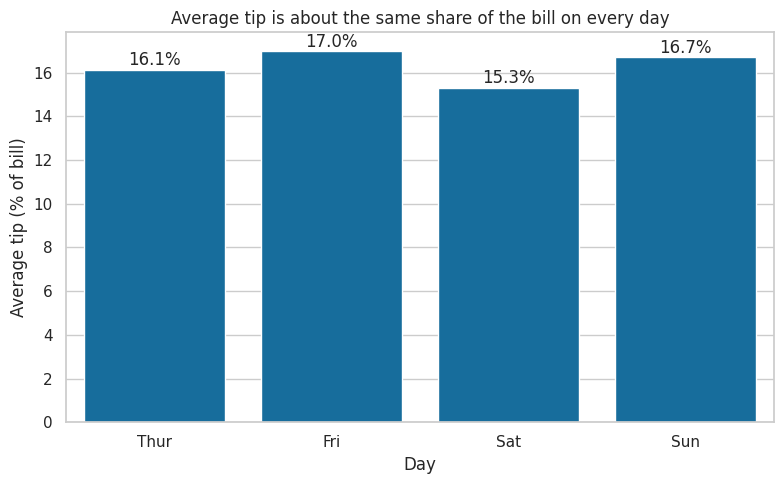

Takeaway: average tip as a share of the bill -> Thur: 16.1%, Fri: 17.0%, Sat: 15.3%, Sun: 16.7%.


In [9]:
pct = tips.groupby("day", observed=True)["tip_pct"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=pct.index, y=pct.values, ax=ax)
ax.set(title="Average tip is about the same share of the bill on every day",
       xlabel="Day", ylabel="Average tip (% of bill)", ylim=(0, None))
for i, v in enumerate(pct.values):
    ax.text(i, v + 0.2, f"{v:.1f}%", ha="center")
plt.tight_layout()
plt.show()

print("Takeaway: average tip as a share of the bill -> " + ", ".join(f"{d}: {v:.1f}%" for d, v in pct.items()) + ".")

## 9. Dashboard: four charts in one image
2 by 2 grid, saved at 150 dpi.

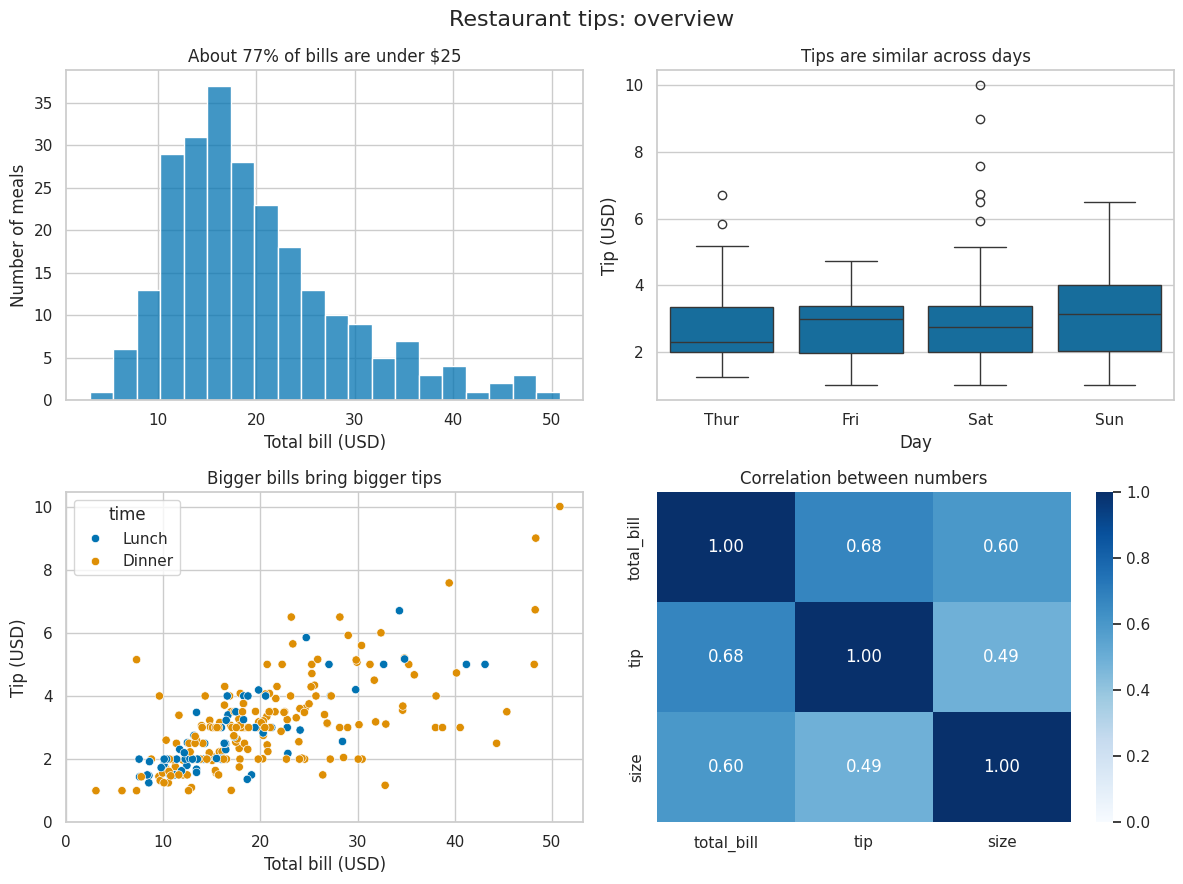

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(tips["total_bill"], bins=20, ax=axes[0, 0])
axes[0, 0].set(title=f"About {pct_under_25:.0%} of bills are under $25",
               xlabel="Total bill (USD)", ylabel="Number of meals")

sns.boxplot(data=tips, x="day", y="tip", ax=axes[0, 1])
axes[0, 1].set(title="Tips are similar across days", xlabel="Day", ylabel="Tip (USD)")

sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", ax=axes[1, 0])
axes[1, 0].set(title="Bigger bills bring bigger tips", xlabel="Total bill (USD)",
               ylabel="Tip (USD)", xlim=(0, None), ylim=(0, None))

sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1, 1])
axes[1, 1].set_title("Correlation between numbers")

fig.suptitle("Restaurant tips: overview", fontsize=16)
plt.tight_layout()
plt.savefig("tips_overview.png", dpi=150)
plt.show()

## 10. Review for honesty
- Bar chart and scatter axes start at zero; nothing is cut off (`tight_layout` used).
- One colour-blind friendly palette throughout, with colour used only to mean time of day in the scatter plot.
- No pie or 3D charts.
- Every chart has a finding-style title, labelled axes with units, and a takeaway.

**Limitations:** the dataset has only 244 meals from one restaurant, and correlation does not show that a bigger bill *causes* a bigger tip.

In [11]:
n = len(tips)
note = (
    f"I used the tips dataset ({n} meals) to make a histogram, box plot, scatter plot, bar chart and an "
    f"annotated correlation heatmap with a colour-blind friendly palette, plus a 2x2 dashboard image saved "
    f"at 150 dpi. About {pct_under_25:.0%} of bills are under $25 (median ${tips['total_bill'].median():.2f}). "
    f"Median tips are similar across days (highest on {top_day}), and tip as a share of the bill is about "
    f"{pct.min():.0f}-{pct.max():.0f}% on every day. Tip rises with the bill (r = {r:.2f}), and the strongest "
    f"correlation in the data is between {pair[0]} and {pair[1]} (r = {val:.2f}). Correlation does not "
    f"prove cause, and the data comes from a single restaurant."
)
print(note)

I used the tips dataset (244 meals) to make a histogram, box plot, scatter plot, bar chart and an annotated correlation heatmap with a colour-blind friendly palette, plus a 2x2 dashboard image saved at 150 dpi. About 77% of bills are under $25 (median $17.80). Median tips are similar across days (highest on Sun), and tip as a share of the bill is about 15-17% on every day. Tip rises with the bill (r = 0.68), and the strongest correlation in the data is between total_bill and tip (r = 0.68). Correlation does not prove cause, and the data comes from a single restaurant.
